# Diamond Inventory & Pricing: Analytics Report

**Business problem:** A diamond retailer wants to know where its inventory value is concentrated, how grade and size affect pricing, and which areas need attention.

**Stakeholders:** Merchandising, pricing and purchasing managers.

**Key questions**
1. How is inventory split by size, cut, colour and clarity, and where does the value sit?
2. How much more does each grade earn once size is accounted for?
3. Are there pricing patterns or risk areas the business should act on?

In [1]:
import pandas as pd, numpy as np, os
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', palette='deep')
os.makedirs('figs',exist_ok=True)
df=pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv')
print('Raw rows:',len(df))

Raw rows: 53940


## 1. Data preparation
Same cleaning as the earlier analysis: remove duplicates, treat zero dimensions as missing and impute by carat decile, remove physically impossible records, and order the categories.

In [2]:
df=df.drop_duplicates()
df[['x','y','z']]=df[['x','y','z']].replace(0,np.nan)
df['cb']=pd.qcut(df['carat'],10,duplicates='drop')
for c in ['x','y','z']:
    df[c]=df[c].fillna(df.groupby('cb',observed=True)[c].transform('median'))
df=df.drop(columns='cb')
bad=(df.y>20)|(df.z>20)|(df.depth<40)|(df.depth>80)|(df.table>90)
df=df[~bad].copy()
cut=['Fair','Good','Very Good','Premium','Ideal']; col=list('DEFGHIJ'); cla=['I1','SI2','SI1','VS2','VS1','VVS2','VVS1','IF']
df['cut']=pd.Categorical(df.cut,cut,ordered=True); df['color']=pd.Categorical(df.color,col,ordered=True); df['clarity']=pd.Categorical(df.clarity,cla,ordered=True)
df['price_per_carat']=df.price/df.carat
df['band']=pd.cut(df.carat,[0,.5,1,1.5,2,6],labels=['0-0.5','0.5-1','1-1.5','1.5-2','2+'])
n=len(df); tot=df.price.sum()
print('Clean rows:',n)

Clean rows: 53790


## 2. Headline KPIs

In [3]:
kpi=pd.Series({'Total diamonds':n,'Total inventory value ($)':tot,'Average price ($)':df.price.mean(),'Median price ($)':df.price.median(),'Average carat':df.carat.mean(),'Price per carat ($, weighted)':tot/df.carat.sum(),'Premium + Ideal share (%)':df.cut.isin(['Premium','Ideal']).mean()*100})
kpi.round(2)

Total diamonds                   5.379000e+04
Total inventory value ($)        2.115457e+08
Average price ($)                3.932810e+03
Median price ($)                 2.401000e+03
Average carat                    8.000000e-01
Price per carat ($, weighted)    4.929900e+03
Premium + Ideal share (%)        6.550000e+01
dtype: float64

## 3. Where is the inventory value? (units vs value by size)

       units     value  avg_price  units_%  value_%
band                                               
0-0.5  18863  15837760      839.6     35.1      7.5
0.5-1  17474  49131242     2811.7     32.5     23.2
1-1.5  12037  78427444     6515.5     22.4     37.1
1.5-2   3544  40141828    11326.7      6.6     19.0
2+      1872  28007387    14961.2      3.5     13.2


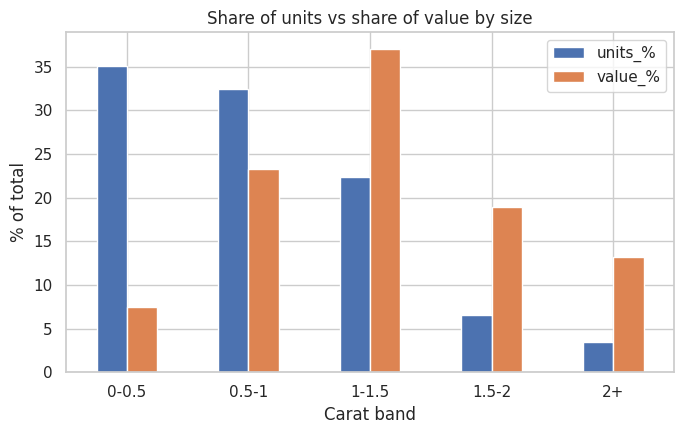

Top 10% of stones hold 34.4 % of value


In [4]:
g=df.groupby('band',observed=True).agg(units=('price','size'),value=('price','sum'),avg_price=('price','mean'))
g['units_%']=g.units/n*100; g['value_%']=g.value/tot*100
print(g.round(1))
ax=g[['units_%','value_%']].plot(kind='bar',figsize=(7,4.5),rot=0); ax.set_ylabel('% of total'); ax.set_xlabel('Carat band'); ax.set_title('Share of units vs share of value by size')
plt.tight_layout(); plt.savefig('figs/units_vs_value_band.png',dpi=130); plt.show()
print('Top 10% of stones hold',round(df.nlargest(int(.1*n),'price').price.sum()/tot*100,1),'% of value')

## 4. Clarity: where is capital tied up?

         units     value  avg_carat  units_%  value_%
clarity                                              
I1         740   2904704        1.3      1.4      1.4
SI2       9149  46263507        1.1     17.0     21.9
SI1      13031  52064637        0.9     24.2     24.6
VS2      12229  48032351        0.8     22.7     22.7
VS1       8154  31328137        0.7     15.2     14.8
VVS2      5056  16616708        0.6      9.4      7.9
VVS1      3647   9214521        0.5      6.8      4.4
IF        1784   5121096        0.5      3.3      2.4


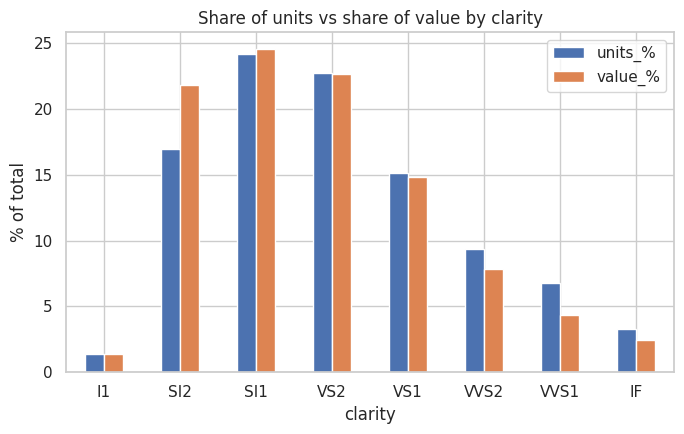

I1+SI2: units % 18.4 | value % 23.2 | avg carat 1.09 vs overall 0.8


In [5]:
c=df.groupby('clarity',observed=True).agg(units=('price','size'),value=('price','sum'),avg_carat=('carat','mean'))
c['units_%']=c.units/n*100; c['value_%']=c.value/tot*100
print(c.round(1))
ax=c[['units_%','value_%']].plot(kind='bar',figsize=(7,4.5),rot=0); ax.set_ylabel('% of total'); ax.set_title('Share of units vs share of value by clarity')
plt.tight_layout(); plt.savefig('figs/units_vs_value_clarity.png',dpi=130); plt.show()
low=df.clarity.isin(['I1','SI2'])
print('I1+SI2: units %',round(low.mean()*100,1),'| value %',round(df[low].price.sum()/tot*100,1),'| avg carat',round(df[low].carat.mean(),2),'vs overall',round(df.carat.mean(),2))

## 5. Pricing grid: price per carat by clarity and colour (1 to 1.5 ct stones)

color          D        E        F       G       H       I       J
clarity                                                           
I1        3412.0   3111.0   3129.0  2867.0  2940.0  2489.0  2303.0
SI2       4564.0   4401.0   4231.0  4142.0  4131.0  3856.0  3551.0
SI1       5593.0   5277.0   5089.0  4877.0  4813.0  4317.0  3938.0
VS2       7157.0   6726.0   6594.0  6157.0  5311.0  4690.0  4117.0
VS1       8118.0   7828.0   7475.0  6884.0  5720.0  4994.0  4396.0
VVS2     10611.0   9464.0   8878.0  7865.0  6231.0  5560.0  4605.0
VVS1     12449.0  10948.0  10018.0  8293.0  6704.0  5750.0  4889.0
IF       15624.0  11884.0  10785.0  8667.0  6965.0  6068.0  4931.0


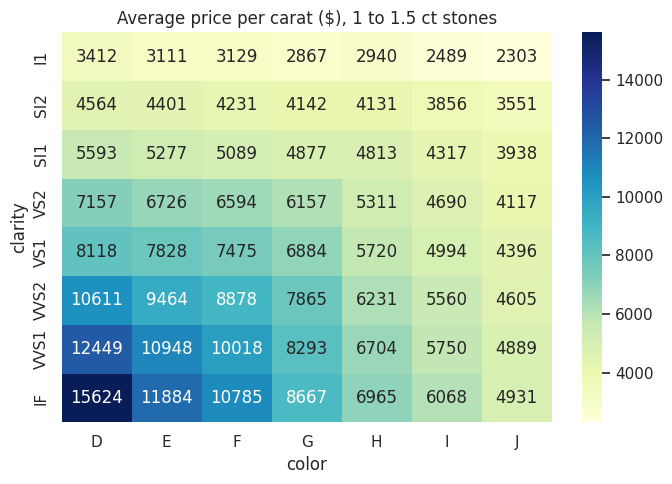

clarity
I1       2937.0
SI2      4184.0
SI1      4870.0
VS2      5901.0
VS1      6552.0
VVS2     8323.0
VVS1     9086.0
IF      10267.0
Name: price_per_carat, dtype: float64


In [6]:
s=df[(df.carat>=1)&(df.carat<1.5)]
grid=s.pivot_table(index='clarity',columns='color',values='price_per_carat',aggfunc='mean',observed=True).round(0)
print(grid)
plt.figure(figsize=(7,5)); sns.heatmap(grid,annot=True,fmt='.0f',cmap='YlGnBu'); plt.title('Average price per carat ($), 1 to 1.5 ct stones'); plt.tight_layout(); plt.savefig('figs/heatmap_ppc.png',dpi=130); plt.show()
print(s.groupby('clarity',observed=True).price_per_carat.mean().round(0))

## 6. Cut premium by size band

cut      Fair    Good  Very Good  Premium   Ideal
band                                             
0-0.5  2392.0  2079.0     2165.0   2372.0  2430.0
0.5-1  3327.0  3757.0     3835.0   3746.0  3798.0
1-1.5  4261.0  5108.0     5642.0   5380.0  6145.0
1.5-2  5296.0  6396.0     7020.0   6941.0  7379.0
2+     5300.0  6916.0     7184.0   7006.0  7295.0


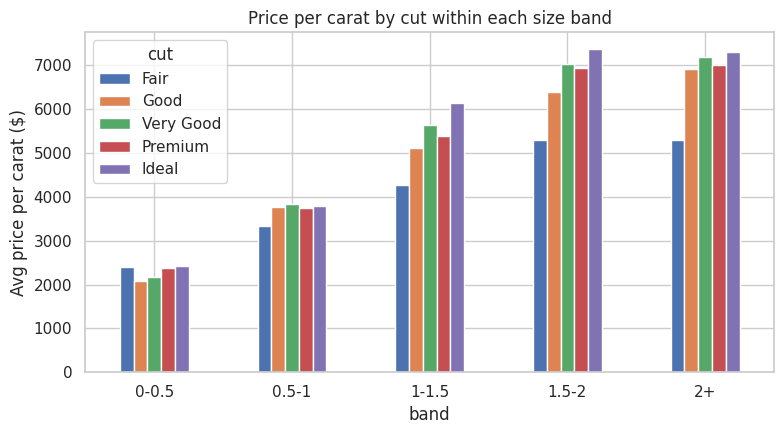

In [7]:
cp=df.pivot_table(index='band',columns='cut',values='price_per_carat',aggfunc='mean',observed=True).round(0)
print(cp)
ax=cp.plot(kind='bar',figsize=(8,4.5),rot=0); ax.set_ylabel('Avg price per carat ($)'); ax.set_title('Price per carat by cut within each size band')
plt.tight_layout(); plt.savefig('figs/ppc_cut_band.png',dpi=130); plt.show()

## 7. The 1.0 carat threshold

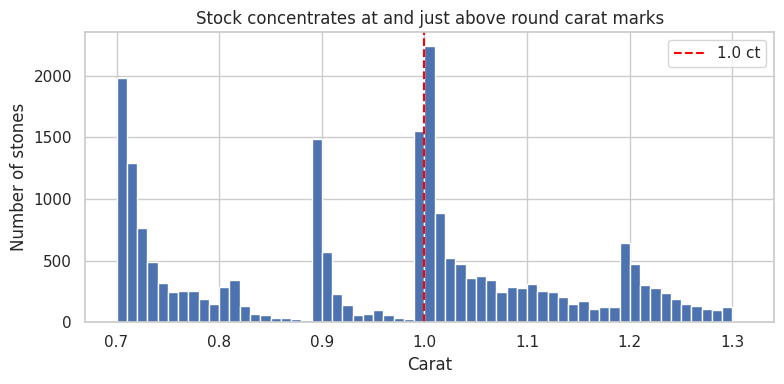

0.95-1.00 ct: 281 | 1.00-1.05 ct: 5667
Avg price per carat 0.90-0.99: 4335 | 1.00-1.09: 5435 | jump %: 25.4


In [8]:
r=df[(df.carat>=0.7)&(df.carat<=1.3)]
plt.figure(figsize=(8,4)); plt.hist(r.carat,bins=np.arange(0.7,1.31,0.01),color='C0'); plt.axvline(1.0,color='red',ls='--',label='1.0 ct'); plt.xlabel('Carat'); plt.ylabel('Number of stones'); plt.title('Stock concentrates at and just above round carat marks'); plt.legend(); plt.tight_layout(); plt.savefig('figs/carat_threshold.png',dpi=130); plt.show()
below=df[(df.carat>=0.9)&(df.carat<1.0)]; above=df[(df.carat>=1.0)&(df.carat<1.1)]
print('0.95-1.00 ct:',((df.carat>=.95)&(df.carat<1)).sum(),'| 1.00-1.05 ct:',((df.carat>=1)&(df.carat<1.05)).sum())
print('Avg price per carat 0.90-0.99:',round(below.price_per_carat.mean()),'| 1.00-1.09:',round(above.price_per_carat.mean()),'| jump %:',round((above.price_per_carat.mean()/below.price_per_carat.mean()-1)*100,1))

## 8. Findings
1. **Value is concentrated in larger stones.** Stones up to 0.5 ct are 35.1% of units but 7.5% of value; stones above 1 ct are 32.5% of units but 69.3% of value.
2. **Capital is tied up in low-clarity stones.** I1 and SI2 stones are about 18% of units but about 23% of value, and they sell at the lowest price per carat.
3. **Grades earn a clear, size-adjusted premium.** In 1 to 1.5 ct stones, IF earns about 3.5 times the price per carat of I1.
4. **Cut matters mainly in larger stones.** Ideal earns about 44% more per carat than Fair at 1 to 1.5 ct, but almost nothing extra under 0.5 ct.
5. **Round-number effect.** Price per carat jumps about 25% at 1.0 ct, and stock piles up just above the mark.

## 9. Recommendations
1. Use the price-per-carat grid to set prices by size band first, then clarity and colour.
2. Review small-stone holdings: slow-moving, low-value units tie up space and handling cost.
3. Reduce exposure to large I1/SI2 stones when purchasing.
4. Promote 0.90 to 0.99 ct stones as a value alternative to 1.0 ct; price 1.0+ stones with the premium.
5. Position D to G for premium customers and H to J for value-focused customers.
6. Next steps: add sales, margin and date data to measure turnover, and build a price-prediction model.